In [1]:

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../inputN Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        os.path.join(dirname, filename)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
folder_location = '/kaggle/input/datasets/sammywanjohi/brats-africa-2026/BraTS-Africa'
os.listdir(folder_location)

['95_Glioma', '51_OtherNeoplasms']

In [3]:
!pip install nibabel pydicom

In [4]:
import nibabel as nib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import warnings
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split

glioma_path = os.path.join(folder_location, '95_Glioma')
other_path = os.path.join(folder_location, '51_OtherNeoplasms')

# Explore folder structures
print(" Glioma Folder Structure")
for item in os.listdir(glioma_path)[:5]:  # Show first 5 items
    print(f"- {item}")
    subpath = os.path.join(glioma_path, item)
    if os.path.isdir(subpath):
        print(f"  Contains: {os.listdir(subpath)[:3]}")  # First 3 files

print("\n Other Neoplasms Folder Structure ")
for item in os.listdir(other_path)[:5]:
    print(f"- {item}")
    subpath = os.path.join(other_path, item)
    if os.path.isdir(subpath):
        print(f"  Contains: {os.listdir(subpath)[:3]}")

 Glioma Folder Structure
- BraTS-SSA-00068-000
  Contains: ['BraTS-SSA-00068-000-t1n.nii', 'BraTS-SSA-00068-000-seg.nii', 'BraTS-SSA-00068-000-t2f.nii']
- BraTS-SSA-00120-000
  Contains: ['BraTS-SSA-00120-000-t2w.nii', 'BraTS-SSA-00120-000-t2f.nii', 'BraTS-SSA-00120-000-seg.nii']
- BraTS-SSA-00097-000
  Contains: ['BraTS-SSA-00097-000-t2w.nii', 'BraTS-SSA-00097-000-seg.nii', 'BraTS-SSA-00097-000-t1n.nii']
- BraTS-SSA-00155-000
  Contains: ['BraTS-SSA-00155-000-t2w.nii', 'BraTS-SSA-00155-000-t1n.nii', 'BraTS-SSA-00155-000-seg.nii']
- BraTS-SSA-00137-000
  Contains: ['BraTS-SSA-00137-000-t1n.nii', 'BraTS-SSA-00137-000-t2f.nii', 'BraTS-SSA-00137-000-t2w.nii']

 Other Neoplasms Folder Structure 
- BraTS-SSA-00203-000
  Contains: ['BraTS-SSA-00203-000-t2w.nii', 'BraTS-SSA-00203-000-seg.nii', 'BraTS-SSA-00203-000-t2f.nii']
- BraTS-SSA-00185-000
  Contains: ['BraTS-SSA-00185-000-t1n.nii', 'BraTS-SSA-00185-000-t1c.nii', 'BraTS-SSA-00185-000-t2f.nii']
- BraTS-SSA-00151-000
  Contains: ['BraTS-S

Dataset Summary 
Glioma patients/cases: 95
Other Neoplasms patients/cases: 51
Total: 146


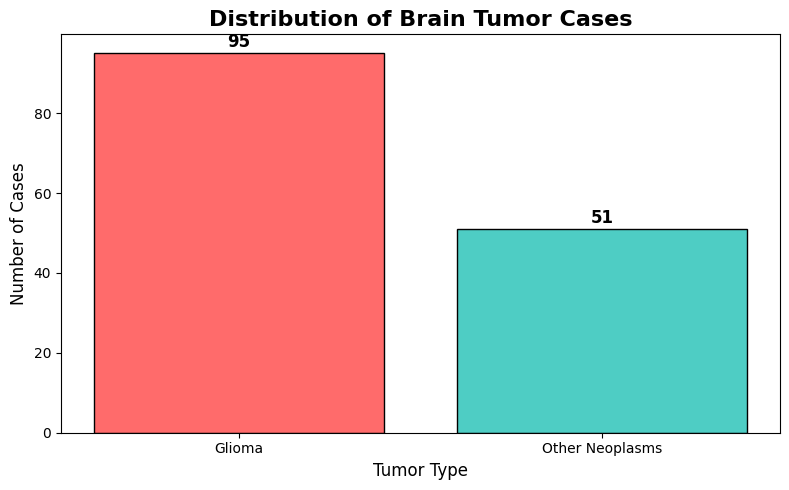

In [5]:
# Count patients/scans per tumor type
glioma_patients = [d for d in os.listdir(glioma_path) if os.path.isdir(os.path.join(glioma_path, d))]
other_patients = [d for d in os.listdir(other_path) if os.path.isdir(os.path.join(other_path, d))]

print("Dataset Summary ")
print(f"Glioma patients/cases: {len(glioma_patients)}")
print(f"Other Neoplasms patients/cases: {len(other_patients)}")
print(f"Total: {len(glioma_patients) + len(other_patients)}")

# Create a simple visualization
plt.figure(figsize=(8, 5))
categories = ['Glioma', 'Other Neoplasms']
counts = [len(glioma_patients), len(other_patients)]
colors = ['#FF6B6B', '#4ECDC4']
bars = plt.bar(categories, counts, color=colors, edgecolor='black')
plt.title('Distribution of Brain Tumor Cases', fontsize=16, fontweight='bold')
plt.ylabel('Number of Cases', fontsize=12)
plt.xlabel('Tumor Type', fontsize=12)

for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
             str(count), ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

In [6]:
def load_sample_nifti(tumor_type='Glioma'):
    """
    Load a sample NIfTI file from the dataset
    """
    if tumor_type == 'Glioma':
        base_path = glioma_path
    else:
        base_path = other_path

    # Get first patient folder
    patients = [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))]
    if not patients:
        print(f"No patients found in {tumor_type} folder")
        return None

    patient_folder = os.path.join(base_path, patients[0])

    # Look for NIfTI files (.nii or .nii.gz)
    nifti_files = []
    for root, dirs, files in os.walk(patient_folder):
        for file in files:
            if file.endswith('.nii') or file.endswith('.nii.gz'):
                nifti_files.append(os.path.join(root, file))

    if not nifti_files:
        print(f"No NIfTI files found in {patient_folder}")
        return None

    print(f"Loading sample from {tumor_type} - Patient: {patients[0]}")
    print(f"Found {len(nifti_files)} NIfTI file(s)")

    # Load first NIfTI file
    img = nib.load(nifti_files[0])
    data = img.get_fdata()

    return data, img, nifti_files[0]

# Test loading from Glioma
glioma_data, glioma_img, glioma_file = load_sample_nifti('Glioma')
if glioma_data is not None:
    print(f"\nImage shape: {glioma_data.shape}")
    print(f"Data type: {glioma_data.dtype}")
    print(f"Pixel value range: {glioma_data.min():.2f} - {glioma_data.max():.2f}")

# test loading from other neoplasms
other_data, other_img, other_file = load_sample_nifti('Other Neoplasms')
if other_data is not None:
    print(f"\nImage shape: {other_data.shape}")
    print(f"Data type: {other_data.dtype}")
    print(f"Pixel value range: {other_data.min():.2f} - {other_data.max():.2f}")

Loading sample from Glioma - Patient: BraTS-SSA-00068-000
Found 5 NIfTI file(s)

Image shape: (240, 240, 155)
Data type: float64
Pixel value range: 0.00 - 871.00
Loading sample from Other Neoplasms - Patient: BraTS-SSA-00203-000
Found 5 NIfTI file(s)

Image shape: (240, 240, 155)
Data type: float64
Pixel value range: 0.00 - 1123.00


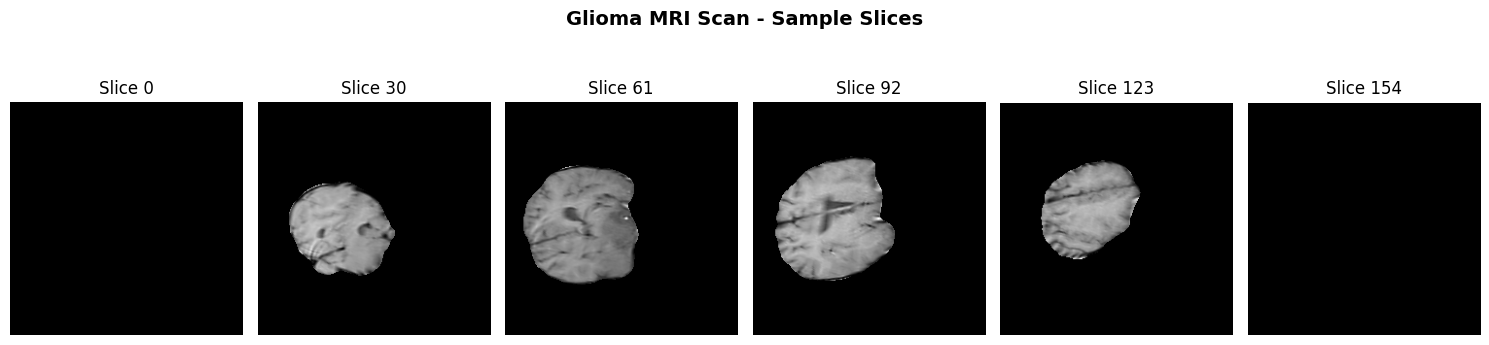

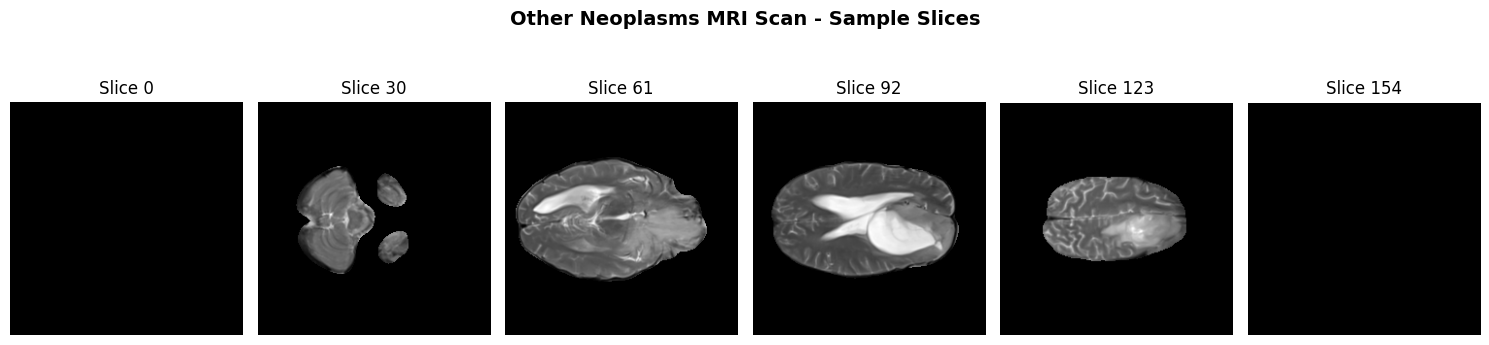

In [7]:
def visualize_mri_slices(data, title="MRI Scan", num_slices=6):
    """
    Display multiple slices from a 3D MRI volume
    """
    if data is None:
        print("No data to visualize")
        return

    # Get dimensions
    depth = data.shape[2] if len(data.shape) > 2 else 1

    # Select evenly spaced slices
    if depth > num_slices:
        slice_indices = np.linspace(0, depth-1, num_slices, dtype=int)
    else:
        slice_indices = range(depth)
        num_slices = depth

    fig, axes = plt.subplots(1, num_slices, figsize=(15, 4))
    if num_slices == 1:
        axes = [axes]

    for i, idx in enumerate(slice_indices):
        if len(data.shape) == 3:
            slice_data = data[:, :, idx]
        else:
            slice_data = data

        im = axes[i].imshow(slice_data, cmap='gray')
        axes[i].set_title(f'Slice {idx}')
        axes[i].axis('off')

    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Visualize the sample Glioma and Other Neoplasms scan
if glioma_data is not None:
    visualize_mri_slices(glioma_data, title="Glioma MRI Scan - Sample Slices")
if other_data is not None:
    visualize_mri_slices(other_data, title="Other Neoplasms MRI Scan - Sample Slices")


 Glioma - Intensity Statistics 
Total pixels: 8,928,000
Non-zero pixels: 1,218,829 (13.65%)
Mean intensity: 320.28
Median intensity: 338.00
Std deviation: 79.18
Min intensity: 1.00
Max intensity: 871.00


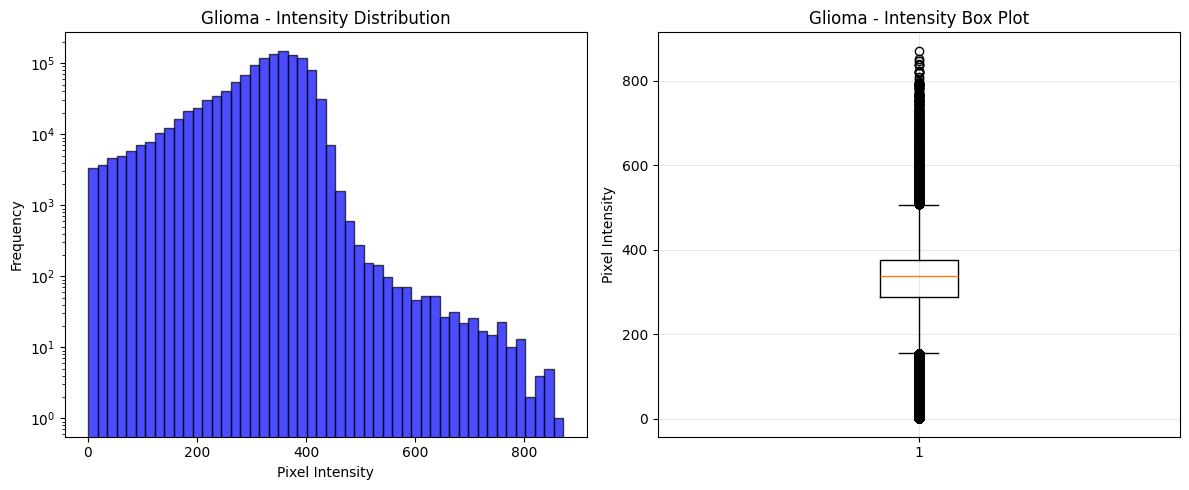

Loading sample from Other Neoplasms - Patient: BraTS-SSA-00203-000
Found 5 NIfTI file(s)

 Other Neoplasms - Intensity Statistics 
Total pixels: 8,928,000
Non-zero pixels: 1,701,410 (19.06%)
Mean intensity: 413.29
Median intensity: 370.00
Std deviation: 180.34
Min intensity: 1.00
Max intensity: 1123.00


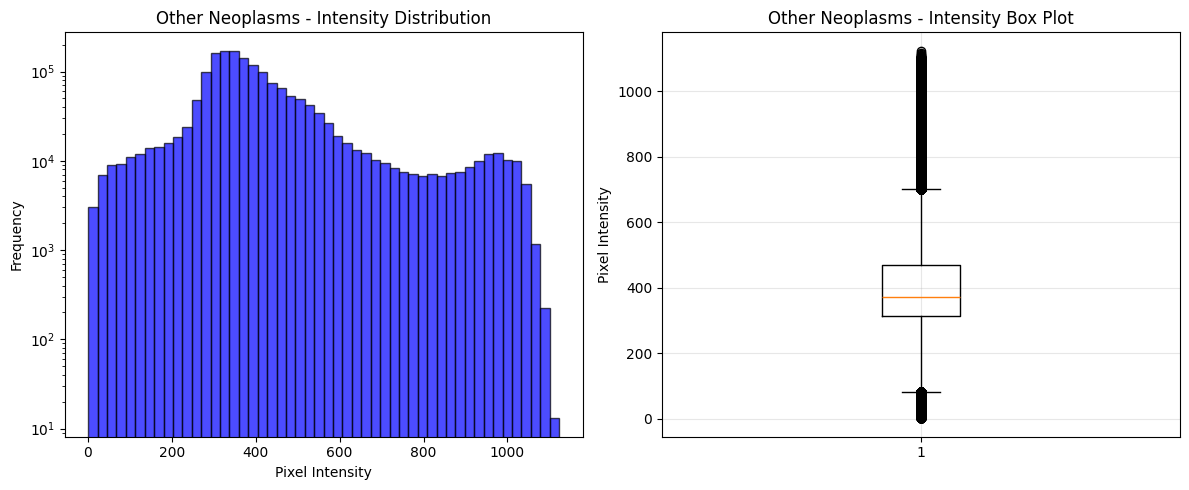

In [8]:
def analyze_intensity_distribution(data, tumor_type):
    """
    Analyze pixel intensity statistics
    """
    if data is None:
        return

    # Flatten the array
    flat_data = data.flatten()

    # Remove zeros (background) for better analysis
    non_zero = flat_data[flat_data > 0]

    print(f"\n {tumor_type} - Intensity Statistics ")
    print(f"Total pixels: {len(flat_data):,}")
    print(f"Non-zero pixels: {len(non_zero):,} ({len(non_zero)/len(flat_data)*100:.2f}%)")
    print(f"Mean intensity: {np.mean(non_zero):.2f}")
    print(f"Median intensity: {np.median(non_zero):.2f}")
    print(f"Std deviation: {np.std(non_zero):.2f}")
    print(f"Min intensity: {np.min(non_zero):.2f}")
    print(f"Max intensity: {np.max(non_zero):.2f}")

    # Plot distribution
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Histogram
    axes[0].hist(non_zero, bins=50, alpha=0.7, color='blue', edgecolor='black')
    axes[0].set_title(f'{tumor_type} - Intensity Distribution')
    axes[0].set_xlabel('Pixel Intensity')
    axes[0].set_ylabel('Frequency')
    axes[0].set_yscale('log')

    # Box plot
    axes[1].boxplot(non_zero, vert=True)
    axes[1].set_title(f'{tumor_type} - Intensity Box Plot')
    axes[1].set_ylabel('Pixel Intensity')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Analyze both tumor types
if glioma_data is not None:
    analyze_intensity_distribution(glioma_data, "Glioma")

# Load and analyze Other Neoplasms sample
other_data, other_img, other_file = load_sample_nifti('Other Neoplasms')
if other_data is not None:
    analyze_intensity_distribution(other_data, "Other Neoplasms")

In [9]:

def analyze_segmentation_mask(nifti_path):
    """Check if segmentation masks exist and their label distribution"""
    import nibabel as nib
    import numpy as np
    import matplotlib.pyplot as plt

    img = nib.load(nifti_path)
    mask = img.get_fdata()

    print(f"Mask shape: {mask.shape}")
    print(f"Unique labels: {np.unique(mask)}")

    # BraTS standard labels: 1=necrosis, 2=edema, 3=non-enhancing, 4=enhancing
    for label in [1, 2, 3, 4]:
        if label in mask:
            voxel_count = np.sum(mask == label)
            print(f"  Label {label}: {voxel_count} voxels ({voxel_count/mask.size*100:.2f}%)")

    # Visualize mask overlay
    plt.figure(figsize=(12, 4))
    mid_slice = mask.shape[2] // 2
    plt.imshow(mask[:, :, mid_slice], cmap='tab10')
    plt.title(f"Segmentation Mask - Slice {mid_slice}")
    plt.colorbar()
    plt.show()

In [10]:
def get_nifti_metadata(nifti_path):
    """Extract physical spacing and orientation info"""
    import nibabel as nib

    img = nib.load(nifti_path)
    header = img.header

    print(f"Voxel spacing (mm): {header.get_zooms()}")
    print(f"Data shape: {header.get_data_shape()}")
    print(f"Data type: {header.get_data_dtype()}")

    # Affine matrix shows orientation
    affine = img.affine
    print(f"Orientation (RAS/LAS/etc.): {nib.aff2axcodes(affine)}")

    return header.get_zooms()

In [11]:

# Apply to samples
if glioma_file:
    spacing = get_nifti_metadata(glioma_file)
if other_file:
    spacing = get_nifti_metadata(other_file)


Voxel spacing (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Data shape: (240, 240, 155)
Data type: float32
Orientation (RAS/LAS/etc.): ('R', 'A', 'S')
Voxel spacing (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Data shape: (240, 240, 155)
Data type: float32
Orientation (RAS/LAS/etc.): ('R', 'A', 'S')


In [12]:
from sklearn.model_selection import train_test_split

# Get all patient IDs with their labels
all_patients = []
all_labels = []

for patient in glioma_patients:
    all_patients.append(patient)
    all_labels.append('Glioma')

for patient in other_patients:
    all_patients.append(patient)
    all_labels.append('Other')

# Stratified split
train_patients, temp_patients, train_labels, temp_labels = train_test_split(
    all_patients, all_labels, test_size=0.3, stratify=all_labels, random_state=42
)

val_patients, test_patients, val_labels, test_labels = train_test_split(
    temp_patients, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

print(f"\nDataset Split")
print(f"Train: {len(train_patients)} patients")
print(f"Validation: {len(val_patients)} patients")
print(f"Test: {len(test_patients)} patients")



Dataset Split
Train: 102 patients
Validation: 22 patients
Test: 22 patients


In [13]:
def identify_sequences(patient_folder):
    """Identify which MRI sequences are present"""
    sequences = {'T1': None, 'T1c': None, 'T2': None, 'FLAIR': None, 'SEG': None}

    for file in os.listdir(patient_folder):
        file_lower = file.lower()
        if 't1' in file_lower and 'ce' not in file_lower:
            sequences['T1'] = file
        elif 't1ce' in file_lower or 't1gd' in file_lower:
            sequences['T1c'] = file
        elif 't2' in file_lower and 'flair' not in file_lower:
            sequences['T2'] = file
        elif 'flair' in file_lower:
            sequences['FLAIR'] = file
        elif 'seg' in file_lower:
            sequences['SEG'] = file

    return sequences

In [14]:

# Check glioma patient
first_glioma_folder = os.path.join(glioma_path, glioma_patients[0])
sequences = identify_sequences(first_glioma_folder)
print(f"\nSequences for {glioma_patients[0]} ")
for seq, filename in sequences.items():
    status = "available" if filename else "not available"
    print(f"{status} {seq}: {filename if filename else 'Not found'}")


# check for other neoplasms
first_other_folder = os.path.join(other_path, other_patients[0])
sequences = identify_sequences(first_other_folder)
print(f"\nSequences for {other_patients[0]} ")
for seq, filename in sequences.items():
    status = "available" if filename else "not available"
    print(f"{status} {seq}: {filename if filename else 'Not found'}")


Sequences for BraTS-SSA-00068-000 
available T1: BraTS-SSA-00068-000-t1c.nii
not available T1c: Not found
available T2: BraTS-SSA-00068-000-t2w.nii
not available FLAIR: Not found
available SEG: BraTS-SSA-00068-000-seg.nii

Sequences for BraTS-SSA-00203-000 
available T1: BraTS-SSA-00203-000-t1c.nii
not available T1c: Not found
available T2: BraTS-SSA-00203-000-t2f.nii
not available FLAIR: Not found
available SEG: BraTS-SSA-00203-000-seg.nii


In [15]:
def complete_preprocess(nifti_path, target_shape=(128, 128, 128)):
    """
    Full preprocessing pipeline:
    - Load and normalize
    - Resample to isotropic spacing
    - Resize to target shape
    - Extract patches for 3D CNN
    """
    from scipy.ndimage import zoom

    img = nib.load(nifti_path)
    data = img.get_fdata()

    # Normalize
    nonzero = data[data > 0]
    if len(nonzero) > 0:
        data = (data - nonzero.mean()) / (nonzero.std() + 1e-8)

    # Resize to target shape
    current_shape = data.shape
    zoom_factors = [t / c for t, c in zip(target_shape, current_shape)]
    resized = zoom(data, zoom_factors, order=1)

    return resized

In [16]:

# Test
if glioma_file:
    preprocessed = complete_preprocess(glioma_file)
    print(f"\nPreprocessed shape: {preprocessed.shape}")
    print(f"Preprocessed range: {preprocessed.min():.2f} - {preprocessed.max():.2f}")
if other_file:
  preprocessed = complete_preprocess(other_file)
  print(f"\nPreprocessed shape: {preprocessed.shape}")
  print(f"Preprocessed range: {preprocessed.min():.2f} - {preprocessed.max():.2f}")



Preprocessed shape: (128, 128, 128)
Preprocessed range: -4.05 - 6.47

Preprocessed shape: (128, 128, 128)
Preprocessed range: -2.29 - 3.79


In [17]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array(all_labels)
unique_classes = np.unique(classes)
weights = compute_class_weight('balanced', classes=unique_classes, y=classes)
class_weight_dict = dict(zip(unique_classes, weights))

print(f"\n Class Weights (for loss function)")
for tumor_type, weight in class_weight_dict.items():
    print(f"{tumor_type}: {weight:.3f}")


 Class Weights (for loss function)
Glioma: 0.768
Other: 1.431


In [18]:
# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [19]:
# Find patients with segmentation masks
segmentation_patients = []

for path, tumor_type in [(glioma_path, 'Glioma'), (other_path, 'Other')]:
    patients_in_folder = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]

    for patient_id in patients_in_folder:
        patient_folder = os.path.join(path, patient_id)
        files = os.listdir(patient_folder)

        current_patient_sequences = {'t1': None, 't1ce': None, 't2': None, 'flair': None, 'seg': None}

        for file in files:
            file_lower = file.lower()
            if 'seg' in file_lower:
                current_patient_sequences['seg'] = file
            else:
                base_name = file_lower.replace('.nii.gz', '').replace('.nii', '')
                parts = base_name.split('-')
                if len(parts) > 1:
                    seq_identifier = parts[-1]
                    if 't1ce' in seq_identifier or 't1gd' in seq_identifier or seq_identifier == 't1c':
                        current_patient_sequences['t1ce'] = file
                    elif 'flair' in seq_identifier or seq_identifier == 't2f':
                        current_patient_sequences['flair'] = file
                    elif 't2' in seq_identifier and 'flair' not in seq_identifier and seq_identifier != 't2f':
                        current_patient_sequences['t2'] = file
                    elif 't1' in seq_identifier and 'ce' not in seq_identifier and 'gd' not in seq_identifier and seq_identifier != 't1c':
                        current_patient_sequences['t1'] = file

        if current_patient_sequences['seg']:
            has_mri_sequence = any([current_patient_sequences['t1'],
                                    current_patient_sequences['t1ce'],
                                    current_patient_sequences['t2'],
                                    current_patient_sequences['flair']])
            if has_mri_sequence:
                segmentation_patients.append({
                    'patient_id': patient_id,
                    'tumor_type': tumor_type,
                    'folder': patient_folder,
                    't1': current_patient_sequences['t1'],
                    't2': current_patient_sequences['t2'],
                    't1ce': current_patient_sequences['t1ce'],
                    'flair': current_patient_sequences['flair'],
                    'seg': current_patient_sequences['seg']
                })

In [20]:
class BratsSegmentationDataset(Dataset):
    def __init__(self, patients, target_size=(128, 128, 128)):
        self.patients = patients
        self.target_size = target_size

    def __len__(self):
        return len(self.patients)

    def load_and_preprocess(self, file_path):
        img = nib.load(file_path)
        data = img.get_fdata().astype(np.float32)
        nonzero = data[data > 0]
        if len(nonzero) > 0:
            data = (data - nonzero.mean()) / (nonzero.std() + 1e-8)
        return data

    def resize_volume(self, volume, target_shape):
        from scipy.ndimage import zoom
        zoom_factors = [target_shape[i] / volume.shape[i] for i in range(3)]
        return zoom(volume, zoom_factors, order=1)

    def load_seg_mask(self, file_path):
      """Load segmentation mask WITHOUT normalization — labels must stay as integers"""
      img = nib.load(file_path)
      data = img.get_fdata().astype(np.float32)
      return data  # No normalization!

    def __getitem__(self, idx):
        patient = self.patients[idx]
        folder = patient['folder']

        # Load ALL nifti files except the segmentation mask
        all_niftis = [
            f for f in os.listdir(folder)
            if (f.endswith('.nii') or f.endswith('.nii.gz'))
            and 'seg' not in f.lower()
        ]

        # Load segmentation mask
        seg_file = patient['seg']

        # Load and resize each MRI file
        channels = []
        for nifti_file in sorted(all_niftis):  # sorted for consistency
            data = self.load_and_preprocess(os.path.join(folder, nifti_file))
            resized = self.resize_volume(data, self.target_size)
            channels.append(resized)

        # Pad or truncate to exactly 4 channels for model consistency
        max_channels = 4
        while len(channels) < max_channels:
            channels.append(np.zeros(self.target_size, dtype=np.float32))  # pad with zeros
        channels = channels[:max_channels]  # truncate if more than 4

        # Stack into [C, D, H, W]
        image = np.stack(channels, axis=0)

        # load masks as is
        seg = self.load_seg_mask(os.path.join(folder, seg_file))
        seg = self.resize_volume(seg, self.target_size)

        image_tensor = torch.FloatTensor(image)
        seg_tensor = torch.LongTensor(seg.round().astype(np.int64))

        return image_tensor, seg_tensor

In [21]:



class AttentionBlock(nn.Module):
    """Attention Gate for U-Net"""
    def __init__(self, F_g, F_l, F_int):
        super(AttentionBlock, self).__init__()
        self.W_g = nn.Sequential(
            nn.Conv3d(F_g, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm3d(F_int)
        )

        self.W_x = nn.Sequential(
            nn.Conv3d(F_l, F_int, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm3d(F_int)
        )

        self.psi = nn.Sequential(
            nn.Conv3d(F_int, 1, kernel_size=1, stride=1, padding=0, bias=True),
            nn.BatchNorm3d(1),
            nn.Sigmoid()
        )

        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class DoubleConv(nn.Module):
    """Double Convolution Block"""
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm3d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

class AttentionUNet3D(nn.Module):
    """3D Attention U-Net for Brain Tumor Segmentation"""
    def __init__(self, in_channels=4, out_channels=4):  # 4 classes: 0=BG, 1=necrosis, 2=edema, 3=enhancing
        super(AttentionUNet3D, self).__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        # Pooling
        self.pool = nn.MaxPool3d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(256, 512)

        # Decoder with Attention Gates
        self.up4 = nn.ConvTranspose3d(512, 256, kernel_size=2, stride=2)
        self.att4 = AttentionBlock(F_g=256, F_l=256, F_int=128)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose3d(256, 128, kernel_size=2, stride=2)
        self.att3 = AttentionBlock(F_g=128, F_l=128, F_int=64)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose3d(128, 64, kernel_size=2, stride=2)
        self.att2 = AttentionBlock(F_g=64, F_l=64, F_int=32)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose3d(64, 32, kernel_size=2, stride=2)
        self.att1 = AttentionBlock(F_g=32, F_l=32, F_int=16)
        self.dec1 = DoubleConv(64, 32)

        # Output layer
        self.out_conv = nn.Conv3d(32, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder with attention
        d4 = self.up4(b)
        e4_att = self.att4(g=d4, x=e4)
        d4 = torch.cat([e4_att, d4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        e3_att = self.att3(g=d3, x=e3)
        d3 = torch.cat([e3_att, d3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        e2_att = self.att2(g=d2, x=e2)
        d2 = torch.cat([e2_att, d2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        e1_att = self.att1(g=d1, x=e1)
        d1 = torch.cat([e1_att, d1], dim=1)
        d1 = self.dec1(d1)

        # Output
        out = self.out_conv(d1)
        return out


In [22]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, pred, target):
        pred = torch.softmax(pred, dim=1)
        target_one_hot = torch.nn.functional.one_hot(target, num_classes=4).permute(0, 4, 1, 2, 3).float()

        dice = 0
        for c in range(1, 4):  # Skip background
            pred_c = pred[:, c]
            target_c = target_one_hot[:, c]
            intersection = (pred_c * target_c).sum()
            union = pred_c.sum() + target_c.sum()
            dice += (2. * intersection + self.smooth) / (union + self.smooth)

        return 1 - dice / 3  # Average over 3 classes

In [23]:
# Split patients with masks
train_patients, val_patients = train_test_split(
    segmentation_patients, test_size=0.2, random_state=42, stratify=[p['tumor_type'] for p in segmentation_patients]
)

print(f"\nTrain patients: {len(train_patients)}")
print(f"Val patients: {len(val_patients)}")

# Create datasets
train_dataset = BratsSegmentationDataset(train_patients)
val_dataset = BratsSegmentationDataset(val_patients)

# Dataloaders
train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=1, shuffle=False, num_workers=0)


Train patients: 116
Val patients: 30


In [24]:

model = AttentionUNet3D(in_channels=4, out_channels=4).to(device)
criterion = DiceLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5, factor=0.5)

# Training loop
num_epochs = 50
best_val_loss = float('inf')

print("\n Starting Attention U-Net Training")
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

train_losses = []
val_losses = []

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss = 0
    for batch_idx, (images, masks) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1} Train")):
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    avg_train_loss = train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    # Validation
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Epoch {epoch+1} Val"):
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            val_loss += loss.item()

    avg_val_loss = val_loss / len(val_loader)
    val_losses.append(avg_val_loss)

    scheduler.step(avg_val_loss)

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {avg_train_loss:.4f}")
    print(f"Val Loss: {avg_val_loss:.4f}")

    # Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'best_attention_unet.pth')
        print(f" Saved best model with val_loss: {avg_val_loss:.4f}")


 Starting Attention U-Net Training
Model parameters: 22,672,640


Epoch 1 Val: 100%|██████████| 30/30 [01:30<00:00,  3.02s/it]



Epoch 1/50
Train Loss: 0.9634
Val Loss: 0.9528
 Saved best model with val_loss: 0.9528


Epoch 2 Val: 100%|██████████| 30/30 [00:56<00:00,  1.88s/it]



Epoch 2/50
Train Loss: 0.9482
Val Loss: 0.9454
 Saved best model with val_loss: 0.9454


...


Epoch 48/50
Train Loss: 0.4505
Val Loss: 0.5709


Epoch 49 Val: 100%|██████████| 30/30 [00:56<00:00,  1.90s/it]



Epoch 49/50
Train Loss: 0.4498
Val Loss: 0.5437
 Saved best model with val_loss: 0.5437


Epoch 50 Val: 100%|██████████| 30/30 [00:55<00:00,  1.85s/it]


Epoch 50/50
Train Loss: 0.4502
Val Loss: 0.5798


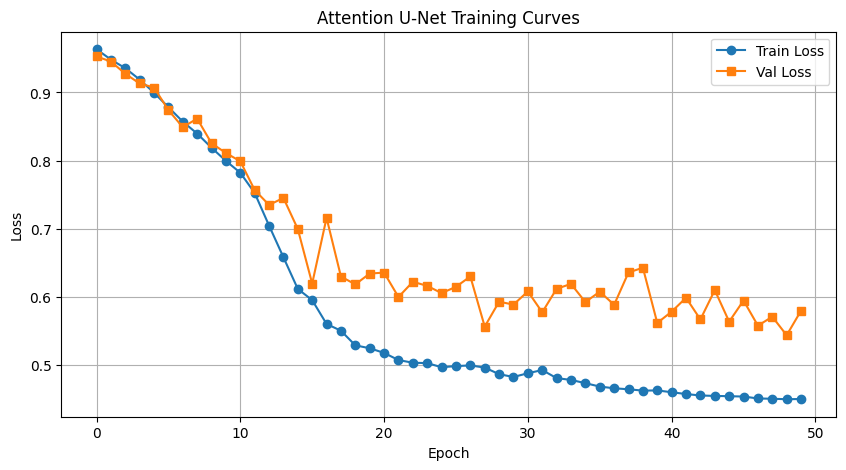

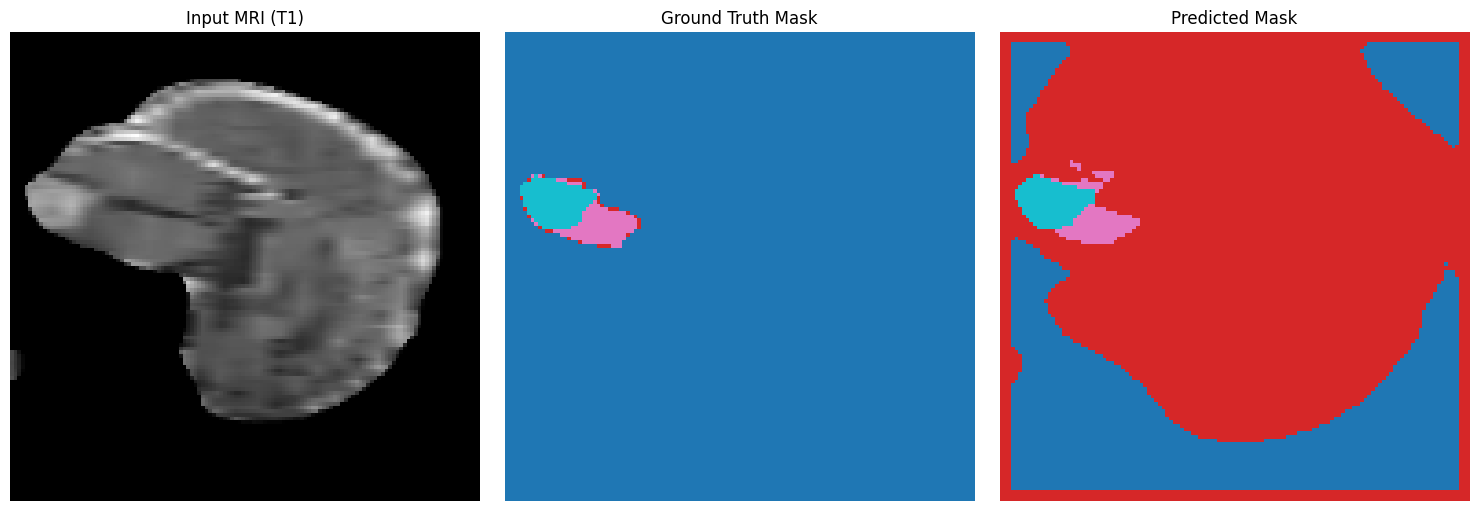


 Training Complete
Best Validation Loss: 0.5437
Model saved as: best_attention_unet.pth


In [25]:

# Plot training curves
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(val_losses, label='Val Loss', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Attention U-Net Training Curves')
plt.legend()
plt.grid(True)
plt.savefig('segmentation_training_curves.png', dpi=150)
plt.show()

# Visualize sample prediction
model.eval()
with torch.no_grad():
    sample_image, sample_mask = next(iter(val_loader))
    sample_image = sample_image.to(device)
    prediction = model(sample_image)
    pred_mask = torch.argmax(prediction, dim=1)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
mid_slice = sample_image.shape[3] // 2

axes[0].imshow(sample_image[0, 0, mid_slice].cpu(), cmap='gray')
axes[0].set_title('Input MRI (T1)')
axes[0].axis('off')

axes[1].imshow(sample_mask[0, mid_slice].cpu(), cmap='tab10', vmin=0, vmax=3)
axes[1].set_title('Ground Truth Mask')
axes[1].axis('off')

axes[2].imshow(pred_mask[0, mid_slice].cpu(), cmap='tab10', vmin=0, vmax=3)
axes[2].set_title('Predicted Mask')
axes[2].axis('off')

plt.tight_layout()
plt.savefig('segmentation_results.png', dpi=150)
plt.show()

print("\n Training Complete")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Model saved as: best_attention_unet.pth")

Calculating Dice Scores on Validation Set...


Evaluating: 100%|██████████| 30/30 [00:55<00:00,  1.83s/it]



DICE SCORE RESULTS (from your trained model)
Background          : 0.2404 ± 0.3211
Necrosis            : 0.0047 ± 0.0044
Edema               : 0.7262 ± 0.2021
Enhancing Tumor     : 0.6388 ± 0.3017

Average Tumor Dice  : 0.4566 ± 0.1349


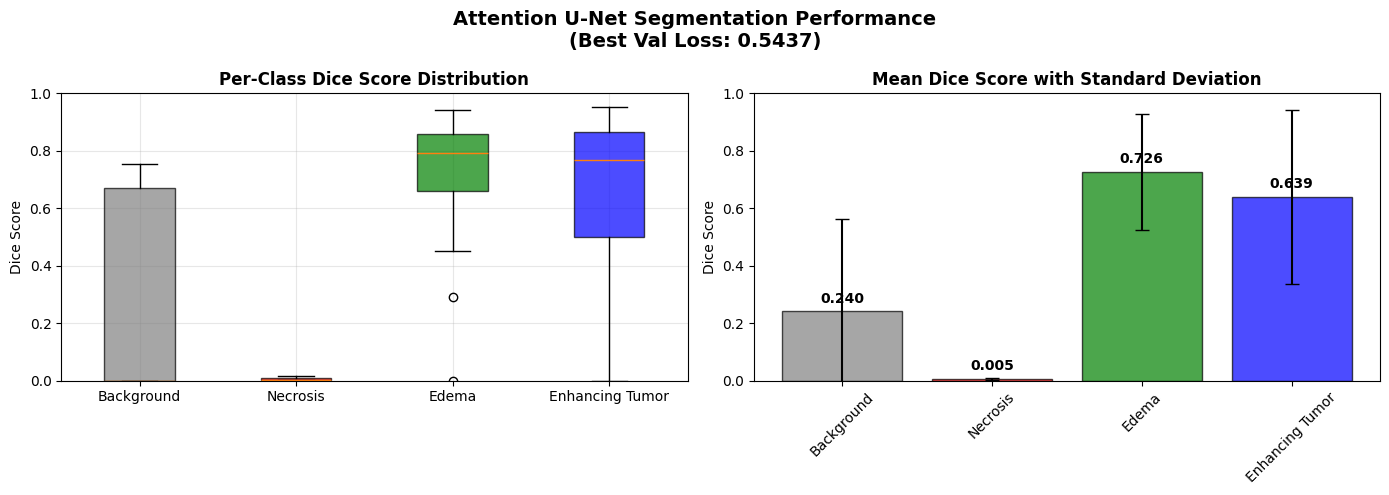


 Dice score visualization saved as 'dice_scores_from_trained_model.png'


In [26]:
# Calculate Dice Scores from current model 



def calculate_dice_score_from_logits(pred_logits, target, num_classes=4):
    """
    Calculate Dice Score from model outputs
    pred_logits: raw model outputs (before softmax)
    target: ground truth masks
    """
    pred_classes = torch.argmax(pred_logits, dim=1)
    
    dice_scores = {}
    
    for c in range(num_classes):
        pred_c = (pred_classes == c).float()
        target_c = (target == c).float()
        
        intersection = (pred_c * target_c).sum()
        union = pred_c.sum() + target_c.sum()
        
        if union == 0:
            dice_scores[c] = 1.0 if c == 0 else 0.0
        else:
            dice_scores[c] = (2. * intersection) / union
    
    # Average over tumor classes (1,2,3)
    avg_tumor_dice = (dice_scores[1] + dice_scores[2] + dice_scores[3]) / 3
    
    return dice_scores, avg_tumor_dice

# Evaluate on validation set
model.eval()
all_dice_scores = {0: [], 1: [], 2: [], 3: []}
all_avg_dice = []

print("Calculating Dice Scores on Validation Set...")

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Evaluating"):
        images = images.to(device)
        masks = masks.to(device)
        
        outputs = model(images)
        dice_scores, avg_dice = calculate_dice_score_from_logits(outputs, masks)
        
        for c in range(4):
            all_dice_scores[c].append(dice_scores[c].item())
        all_avg_dice.append(avg_dice.item())

# Calculate statistics
print("\n" + "="*60)
print("DICE SCORE RESULTS (from your trained model)")
print("="*60)

class_names = {0: 'Background', 1: 'Necrosis', 2: 'Edema', 3: 'Enhancing Tumor'}

for c in range(4):
    mean_dice = np.mean(all_dice_scores[c])
    std_dice = np.std(all_dice_scores[c])
    print(f"{class_names[c]:20s}: {mean_dice:.4f} ± {std_dice:.4f}")

print(f"\n{'Average Tumor Dice':20s}: {np.mean(all_avg_dice):.4f} ± {np.std(all_avg_dice):.4f}")


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot of per-class Dice scores
ax1 = axes[0]
data_to_plot = [all_dice_scores[c] for c in range(4)]
bp = ax1.boxplot(data_to_plot, labels=list(class_names.values()), patch_artist=True)
colors = ['gray', 'red', 'green', 'blue']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax1.set_ylabel('Dice Score')
ax1.set_title('Per-Class Dice Score Distribution', fontsize=12, fontweight='bold')
ax1.set_ylim([0, 1])
ax1.grid(True, alpha=0.3)

# Bar chart with mean Dice scores
ax2 = axes[1]
means = [np.mean(all_dice_scores[c]) for c in range(4)]
stds = [np.std(all_dice_scores[c]) for c in range(4)]
bars = ax2.bar(list(class_names.values()), means, yerr=stds, capsize=5, 
               color=colors, edgecolor='black', alpha=0.7)
ax2.set_ylabel('Dice Score')
ax2.set_title('Mean Dice Score with Standard Deviation', fontsize=12, fontweight='bold')
ax2.set_ylim([0, 1])
ax2.tick_params(axis='x', rotation=45)

# Add value labels on bars
for bar, mean in zip(bars, means):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
             f'{mean:.3f}', ha='center', va='bottom', fontweight='bold')

plt.suptitle(f'Attention U-Net Segmentation Performance\n(Best Val Loss: {best_val_loss:.4f})', 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('dice_scores_from_trained_model.png', dpi=150)
plt.show()

print("\n Dice score visualization saved as 'dice_scores_from_trained_model.png'")

Evaluating: 100%|██████████| 30/30 [01:12<00:00,  2.43s/it]


OVERALL CLASSIFICATION METRICS (Validation Set)

Background:
  Precision: 0.4000 ± 0.4899
  Recall:    0.1813 ± 0.2454
  F1-Score:  0.2404 ± 0.3211

Necrosis:
  Precision: 0.0023 ± 0.0022
  Recall:    0.7377 ± 0.1458
  F1-Score:  0.0047 ± 0.0044

Edema:
  Precision: 0.7832 ± 0.2217
  Recall:    0.7112 ± 0.2024
  F1-Score:  0.7262 ± 0.2021

Enhancing Tumor:
  Precision: 0.6199 ± 0.3304
  Recall:    0.8191 ± 0.2172
  F1-Score:  0.6388 ± 0.3017
SKLEARN CLASSIFICATION REPORT (Pixel-level)
                 precision    recall  f1-score   support

     Background       1.00      0.18      0.31  61858528
       Necrosis       0.00      0.80      0.00    141514
          Edema       0.86      0.77      0.81    625837
Enhancing Tumor       0.17      0.73      0.28    288681

       accuracy                           0.19  62914560
      macro avg       0.51      0.62      0.35  62914560
   weighted avg       0.99      0.19      0.31  62914560



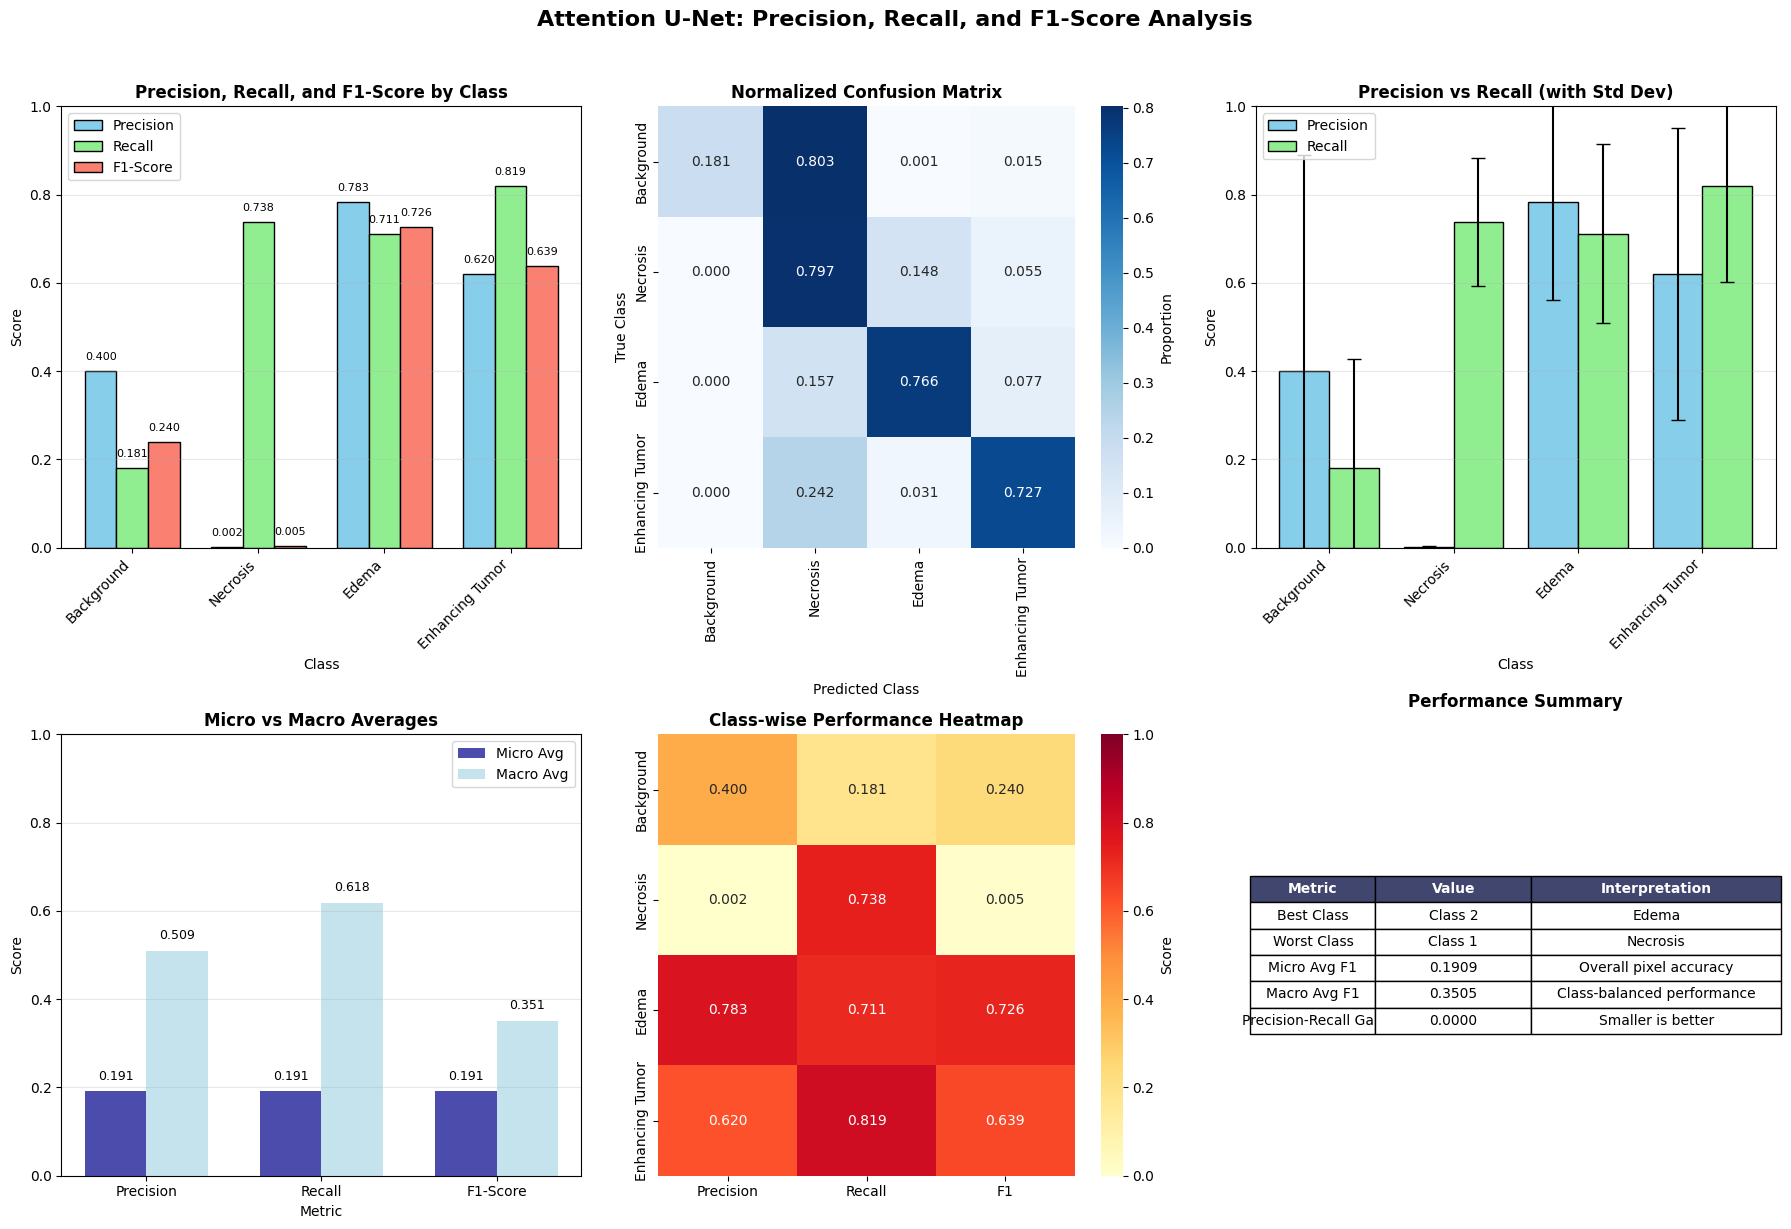

SUMMARY OF RESULTS

Performance Summary:

Micro Averages (Pixel-level):
  - Precision: 0.1909
  - Recall: 0.1909
  - F1-Score: 0.1909

Macro Averages (Class-balanced):
  - Precision: 0.5093
  - Recall: 0.6177
  - F1-Score: 0.3505

Best Performing Class:
  Class 2: Edema
  F1-Score: 0.7262

Worst Performing Class:
  Class 1: Necrosis
  F1-Score: 0.0047

 Visualizations saved as 'precision_recall_f1_analysis.png'


In [27]:
# PRECISION, RECALL, F1-SCORE METRICS


def calculate_per_class_metrics(pred_mask, true_mask, num_classes=4):
    """
    Calculate precision, recall, f1 for each class
    """
    # Flatten the masks
    pred_flat = pred_mask.flatten()
    true_flat = true_mask.flatten()
    
    metrics = {}
    
    for c in range(num_classes):
        # Binary classification for class c vs all others
        pred_binary = (pred_flat == c)
        true_binary = (true_flat == c)
        
        # Calculate metrics
        tp = np.sum(pred_binary & true_binary)
        fp = np.sum(pred_binary & ~true_binary)
        fn = np.sum(~pred_binary & true_binary)
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        
        metrics[c] = {
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'tp': tp,
            'fp': fp,
            'fn': fn
        }
    
    return metrics

# Evaluate on validation set
model.eval()
all_metrics = {c: {'precision': [], 'recall': [], 'f1': []} for c in range(4)}
all_predictions = []
all_targets = []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Evaluating"):
        images = images.to(device)
        masks = masks.to(device)
        
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        
        # Convert to numpy
        pred_np = preds.cpu().numpy()
        mask_np = masks.cpu().numpy()
        
        # Store for overall metrics
        all_predictions.extend(pred_np.flatten())
        all_targets.extend(mask_np.flatten())
        
        # Calculate per-batch metrics
        batch_metrics = calculate_per_class_metrics(pred_np, mask_np)
        for c in range(4):
            for metric in ['precision', 'recall', 'f1']:
                all_metrics[c][metric].append(batch_metrics[c][metric])

# Convert to numpy arrays
all_predictions = np.array(all_predictions)
all_targets = np.array(all_targets)

# Calculate overall metrics
print("OVERALL CLASSIFICATION METRICS (Validation Set)")


class_names = {0: 'Background', 1: 'Necrosis', 2: 'Edema', 3: 'Enhancing Tumor'}

# Store final metrics for plotting
final_metrics = {c: {} for c in range(4)}

for c in range(4):
    # Mean metrics across batches
    precision_mean = np.mean(all_metrics[c]['precision'])
    recall_mean = np.mean(all_metrics[c]['recall'])
    f1_mean = np.mean(all_metrics[c]['f1'])
    
    # Standard deviations
    precision_std = np.std(all_metrics[c]['precision'])
    recall_std = np.std(all_metrics[c]['recall'])
    f1_std = np.std(all_metrics[c]['f1'])
    
    final_metrics[c]['precision'] = (precision_mean, precision_std)
    final_metrics[c]['recall'] = (recall_mean, recall_std)
    final_metrics[c]['f1'] = (f1_mean, f1_std)
    
    print(f"\n{class_names[c]}:")
    print(f"  Precision: {precision_mean:.4f} ± {precision_std:.4f}")
    print(f"  Recall:    {recall_mean:.4f} ± {recall_std:.4f}")
    print(f"  F1-Score:  {f1_mean:.4f} ± {f1_std:.4f}")

# Also calculate from sklearn for verification

print("SKLEARN CLASSIFICATION REPORT (Pixel-level)")

print(classification_report(all_targets, all_predictions, target_names=list(class_names.values())))

# Visualizations
fig = plt.figure(figsize=(18, 12))

# 1. Grouped Bar Chart: Precision, Recall, F1 per class
ax1 = plt.subplot(2, 3, 1)
x = np.arange(4)
width = 0.25

precision_vals = [final_metrics[c]['precision'][0] for c in range(4)]
recall_vals = [final_metrics[c]['recall'][0] for c in range(4)]
f1_vals = [final_metrics[c]['f1'][0] for c in range(4)]

bars1 = ax1.bar(x - width, precision_vals, width, label='Precision', color='skyblue', edgecolor='black')
bars2 = ax1.bar(x, recall_vals, width, label='Recall', color='lightgreen', edgecolor='black')
bars3 = ax1.bar(x + width, f1_vals, width, label='F1-Score', color='salmon', edgecolor='black')

ax1.set_xlabel('Class')
ax1.set_ylabel('Score')
ax1.set_title('Precision, Recall, and F1-Score by Class', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(list(class_names.values()), rotation=45, ha='right')
ax1.set_ylim([0, 1])
ax1.legend()
ax1.grid(True, alpha=0.3, axis='y')

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.3f}', ha='center', va='bottom', fontsize=8)

# 2. Confusion Matrix (Normalized)
ax2 = plt.subplot(2, 3, 2)
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(all_targets, all_predictions, labels=[0, 1, 2, 3])
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

sns.heatmap(cm_normalized, annot=True, fmt='.3f', cmap='Blues', 
            xticklabels=list(class_names.values()),
            yticklabels=list(class_names.values()),
            ax=ax2, cbar_kws={'label': 'Proportion'})
ax2.set_title('Normalized Confusion Matrix', fontsize=12, fontweight='bold')
ax2.set_xlabel('Predicted Class')
ax2.set_ylabel('True Class')

# 3. Precision-Recall Trade-off 
ax3 = plt.subplot(2, 3, 3)
x_pos = np.arange(4)
precision_means = [final_metrics[c]['precision'][0] for c in range(4)]
precision_stds = [final_metrics[c]['precision'][1] for c in range(4)]
recall_means = [final_metrics[c]['recall'][0] for c in range(4)]
recall_stds = [final_metrics[c]['recall'][1] for c in range(4)]

ax3.bar(x_pos - 0.2, precision_means, 0.4, yerr=precision_stds, 
        label='Precision', color='skyblue', capsize=5, edgecolor='black')
ax3.bar(x_pos + 0.2, recall_means, 0.4, yerr=recall_stds, 
        label='Recall', color='lightgreen', capsize=5, edgecolor='black')
ax3.set_xlabel('Class')
ax3.set_ylabel('Score')
ax3.set_title('Precision vs Recall (with Std Dev)', fontsize=12, fontweight='bold')
ax3.set_xticks(x_pos)
ax3.set_xticklabels(list(class_names.values()), rotation=45, ha='right')
ax3.set_ylim([0, 1])
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# 4. Micro vs Macro Averages
ax4 = plt.subplot(2, 3, 4)
from sklearn.metrics import precision_recall_fscore_support

# Calculate micro and macro averages
micro_precision = precision_score(all_targets, all_predictions, average='micro')
micro_recall = recall_score(all_targets, all_predictions, average='micro')
micro_f1 = f1_score(all_targets, all_predictions, average='micro')

macro_precision = precision_score(all_targets, all_predictions, average='macro')
macro_recall = recall_score(all_targets, all_predictions, average='macro')
macro_f1 = f1_score(all_targets, all_predictions, average='macro')

x_pos = np.arange(3)
width = 0.35

micro_bars = ax4.bar(x_pos - width/2, [micro_precision, micro_recall, micro_f1], 
                     width, label='Micro Avg', color='darkblue', alpha=0.7)
macro_bars = ax4.bar(x_pos + width/2, [macro_precision, macro_recall, macro_f1], 
                     width, label='Macro Avg', color='lightblue', alpha=0.7)

ax4.set_xlabel('Metric')
ax4.set_ylabel('Score')
ax4.set_title('Micro vs Macro Averages', fontsize=12, fontweight='bold')
ax4.set_xticks(x_pos)
ax4.set_xticklabels(['Precision', 'Recall', 'F1-Score'])
ax4.set_ylim([0, 1])
ax4.legend()
ax4.grid(True, alpha=0.3, axis='y')

# Add value labels
for bars in [micro_bars, macro_bars]:
    for bar in bars:
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)

# 5. Class-wise Performance Heatmap
ax5 = plt.subplot(2, 3, 5)
metrics_matrix = np.array([[final_metrics[c]['precision'][0], 
                            final_metrics[c]['recall'][0], 
                            final_metrics[c]['f1'][0]] for c in range(4)])

sns.heatmap(metrics_matrix, annot=True, fmt='.3f', cmap='YlOrRd',
            xticklabels=['Precision', 'Recall', 'F1'],
            yticklabels=list(class_names.values()),
            ax=ax5, cbar_kws={'label': 'Score'}, vmin=0, vmax=1)
ax5.set_title('Class-wise Performance Heatmap', fontsize=12, fontweight='bold')

# 6. Summary Statistics Table
ax6 = plt.subplot(2, 3, 6)
ax6.axis('tight')
ax6.axis('off')

# Create summary table data
table_data = [
    ['Metric', 'Value', 'Interpretation'],
    ['Best Class', f"Class {np.argmax(f1_vals)}", class_names[np.argmax(f1_vals)]],
    ['Worst Class', f"Class {np.argmin(f1_vals)}", class_names[np.argmin(f1_vals)]],
    ['Micro Avg F1', f'{micro_f1:.4f}', 'Overall pixel accuracy'],
    ['Macro Avg F1', f'{macro_f1:.4f}', 'Class-balanced performance'],
    ['Precision-Recall Gap', f'{abs(micro_precision - micro_recall):.4f}', 'Smaller is better'],
]

table = ax6.table(cellText=table_data, loc='center', cellLoc='center', colWidths=[0.2, 0.25, 0.4])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)

# Style the header row
for i in range(3):
    table[(0, i)].set_facecolor('#40466e')
    table[(0, i)].set_text_props(weight='bold', color='white')

ax6.set_title('Performance Summary', fontsize=12, fontweight='bold', pad=20)

plt.suptitle('Attention U-Net: Precision, Recall, and F1-Score Analysis', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('precision_recall_f1_analysis.png', dpi=150, bbox_inches='tight')
plt.show()


# PRINT SUMMARY


print("SUMMARY OF RESULTS")




print(f"""
Performance Summary:

Micro Averages (Pixel-level):
  - Precision: {micro_precision:.4f}
  - Recall: {micro_recall:.4f}
  - F1-Score: {micro_f1:.4f}

Macro Averages (Class-balanced):
  - Precision: {macro_precision:.4f}
  - Recall: {macro_recall:.4f}
  - F1-Score: {macro_f1:.4f}

Best Performing Class:
  Class {np.argmax(f1_vals)}: {class_names[np.argmax(f1_vals)]}
  F1-Score: {np.max(f1_vals):.4f}

Worst Performing Class:
  Class {np.argmin(f1_vals)}: {class_names[np.argmin(f1_vals)]}
  F1-Score: {np.min(f1_vals):.4f}
""")



print(" Visualizations saved as 'precision_recall_f1_analysis.png'")